# 03 — Estratégia de negócio e interpretação

Este notebook **não refaz o GridSearchCV**. Ele lê os artefatos produzidos pelo notebook 02, mantendo a etapa de análise posterior rápida e evitando treinamento repetido.

As métricas de campanha foram calculadas com previsões out-of-fold do conjunto de treino.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.modeling import load_generated_results

result = load_generated_results(ROOT / "reports" / "generated")

## Campanha por capacidade

In [2]:
display(result["top_k"].round(4))

,top_k,customers_contacted,precision_at_k,recall_at_k,lift_at_k
0,0.1,564,0.5018,0.1429,1.4271
1,0.2,1127,0.4783,0.2721,1.3602
2,0.3,1691,0.4554,0.3887,1.2950
3,0.4,2254,0.4401,0.5008,1.2517
4,0.5,2817,0.4370,0.6214,1.2428


O `lift_at_k` compara a taxa de churn encontrada no grupo priorizado com a prevalência observada no treino. Valores acima de 1 indicam enriquecimento em relação a uma seleção não direcionada.

## Threshold

,threshold,contact_rate,precision,recall,f1
0,0.20,1.0,0.3516,1.0,0.5203
1,0.21,1.0,0.3516,1.0,0.5203
2,0.22,1.0,0.3516,1.0,0.5203
3,0.23,1.0,0.3516,1.0,0.5203
4,0.24,1.0,0.3516,1.0,0.5203
...,...,...,...,...,...
56,0.76,0.0,0.0000,0.0,0.0000
57,0.77,0.0,0.0000,0.0,0.0000
58,0.78,0.0,0.0000,0.0,0.0000
59,0.79,0.0,0.0000,0.0,0.0000


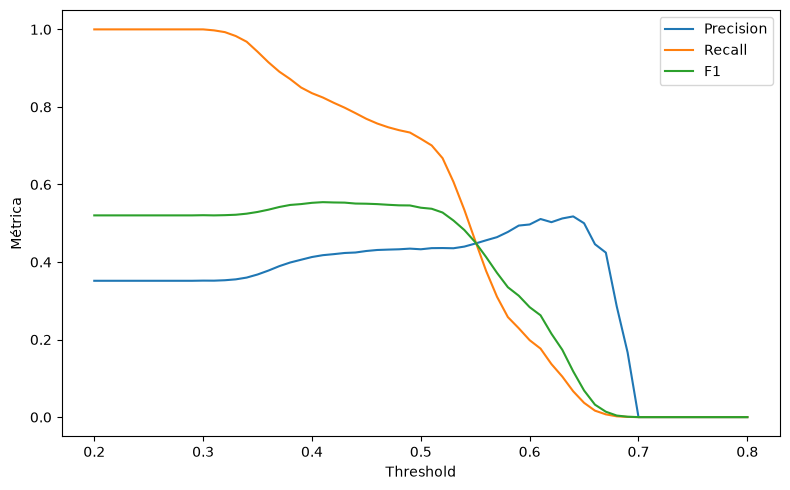

In [3]:
curve = result["thresholds"].copy()
display(curve[["threshold", "contact_rate", "precision", "recall", "f1"]].round(4))

plt.figure(figsize=(8, 5))
plt.plot(curve["threshold"], curve["precision"], label="Precision")
plt.plot(curve["threshold"], curve["recall"], label="Recall")
plt.plot(curve["threshold"], curve["f1"], label="F1")
plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.legend()
plt.tight_layout()
plt.show()

Sem custo de contato, custo do incentivo, valor do cliente e probabilidade de sucesso da retenção, não há base para chamar um threshold de **ótimo econômico**. O gráfico serve para explicitar o trade-off entre alcance e precisão.

## Interpretação do modelo

In [4]:
if result["coefficients"] is not None:
    display(
        result["coefficients"]
        [["feature", "coefficient", "odds_ratio"]]
        .head(20)
        .round(4)
    )
else:
    print("Não há tabela de coeficientes salva para o modelo selecionado.")

,feature,coefficient,odds_ratio
0,Contract_Month-to-month,0.5289,1.6971
1,Contract_Two year,-0.2975,0.7426
2,PaymentMethod_Electronic check,0.2649,1.3032
3,Contract_One year,-0.2331,0.7921
4,PaymentMethod_Credit card (automatic),-0.1163,0.8903
5,PaymentMethod_Mailed check,-0.0985,0.9062
6,OnlineSecurity_No internet service,-0.0740,0.9287
7,OnlineSecurity_Yes,0.0535,1.0549
8,PaymentMethod_Bank transfer (automatic),-0.0519,0.9495
9,StreamingMovies_No internet service,-0.0476,0.9535


Os coeficientes descrevem associações no modelo multivariado e **não demonstram causalidade**. Como o One-Hot Encoder mantém todas as categorias, os odds ratios das dummies não devem ser apresentados como comparação simples contra uma categoria omitida. A leitura principal deve considerar direção, magnitude e coerência com a EDA.